In [4]:
!pip -q install tensorflow-datasets scikit-learn matplotlib seaborn importlib_resources
import os, random, json, pathlib
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:
IMG_SIZE = 160
BATCH_SIZE = 32
MAX_PER_CLASS = 2500 # reduce to 1000 if RAM is limited
# Load Oxford-IIIT Pet: labels are cat/dog and images are RGB.
pets_train, pets_info = tfds.load(
"oxford_iiit_pet",
split="train",
as_supervised=True,
with_info=True
)
pets_test = tfds.load("oxford_iiit_pet", split="test", as_supervised=True)
# Oxford-IIIT Pet label names are typically ["cat", "dog"].
print("Oxford labels:", pets_info.features["label"].names)
def collect_pet_examples(ds):
    xs, ys = [], []
    for image, label in tfds.as_numpy(ds):
        xs.append(image)
        ys.append(int(label)) # 0 cat, 1 dog in the standard dataset label order
    return xs, ys
pet_x1, pet_y1 = collect_pet_examples(pets_train)
pet_x2, pet_y2 = collect_pet_examples(pets_test)
pet_images = pet_x1 + pet_x2
pet_labels = pet_y1 + pet_y2
# Caltech-101 is used for the "neither" class.
caltech, caltech_info = tfds.load(
"caltech101",
split="train",
as_supervised=True,
with_info=True
)
caltech_names = caltech_info.features["label"].names
print("Caltech categories:", len(caltech_names))
catdog_words = ("cat", "dog")
neither_images = []
for image, label in tfds.as_numpy(caltech):
    category = caltech_names[int(label)].lower()
    if not any(word in category for word in catdog_words):
        neither_images.append(image)
    if len(neither_images) >= MAX_PER_CLASS:
        break
# Sample cat, dog, and neither examples.
cat_images = [im for im, lab in zip(pet_images, pet_labels) if lab == 0][:MAX_PER_CLASS]
dog_images = [im for im, lab in zip(pet_images, pet_labels) if lab == 1][:MAX_PER_CLASS]
neither_images = neither_images[:MAX_PER_CLASS]
print("Counts before balancing:", len(cat_images), len(dog_images), len(neither_images))

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

...

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/caltech101/incomplete.G8F1CB_3.0.2/caltech101-train.tfrecord-[0-9][0-9][0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/caltech101/incomplete.G8F1CB_3.0.2/caltech101-test.tfrecord-[0-9][0-9][0-9…

Dataset caltech101 downloaded and prepared to /root/tensorflow_datasets/caltech101/3.0.2. Subsequent calls will reuse this data.
Caltech categories: 102
Counts before balancing: 198 200 2500


In [10]:
LABELS = ["cat", "dog", "neither"]
all_images = cat_images + dog_images + neither_images
all_labels = (
[0] * len(cat_images) +
[1] * len(dog_images) +
[2] * len(neither_images)
)
# Convert images to a common size and scale pixels to [0, 1].
def preprocess_image(image):
    image = tf.convert_to_tensor(image)
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32) / 255.0
    return image.numpy()
X = np.stack([preprocess_image(im) for im in all_images]).astype("float32")
y = np.array(all_labels, dtype="int32")
# First hold out 20%, then split the remaining data into 80% train / 20% validation.
X_train, X_temp, y_train, y_temp = train_test_split(
X, y, test_size=0.20, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)
print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)
print("Train class counts:", {name: int((y_train == i).sum()) for i, name in enumerate(LABELS)})

Train: (2318, 160, 160, 3) Validation: (290, 160, 160, 3) Test: (290, 160, 160, 3)
Train class counts: {'cat': 158, 'dog': 160, 'neither': 2000}


In [11]:
# MobileNetV2 has learned general visual features from ImageNet.
base_model = tf.keras.applications.MobileNetV2(
input_shape=(IMG_SIZE, IMG_SIZE, 3),
include_top=False,
weights="imagenet"
)
base_model.trainable = False
inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
# MobileNetV2 preprocessing expects pixels mapped approximately to [-1, 1].
x = tf.keras.layers.Rescaling(scale=2.0, offset=-1.0)(inputs)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.25)(x)
outputs = tf.keras.layers.Dense(len(LABELS), activation="softmax")(x)
model = tf.keras.Model(inputs, outputs)
model.compile(
optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
loss="sparse_categorical_crossentropy",
metrics=["accuracy"]
)
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/12
73/73 ━━━━━━━━━━━━━━━━━━━━ 25s 185ms/step - accuracy: 0.9154 - loss: 0.2681 - val_accuracy: 0.9862 - val_loss: 0.0502 - learning_rate: 0.0010
Epoch 2/12
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.9905 - loss: 0.0398 - val_accuracy: 0.9931 - val_loss: 0.0279 - learning_rate: 0.0010
Epoch 3/12
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.9957 - loss: 0.0230 - val_accuracy: 0.9931 - val_loss: 0.0206 - learning_rate: 0.0010
Epoch 4/12
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.9978 - loss: 0.0153 - val_accuracy: 0.9966 - val_loss: 0.0158 - learning_rate: 0.0010
Epoch 5/12
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.9978 - loss: 0.0104 - val_accuracy: 0.9931 - val_loss: 0.0150 - learning_rate: 0.0010
Epoch 6/12
73/73 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.9991 - loss: 0.0086 - val_accuracy: 0.9966 - val_loss: 0.0131 - learning_rate: 0.0010
Epoch 7/12
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.9987 - loss: 0.0075 - val_a

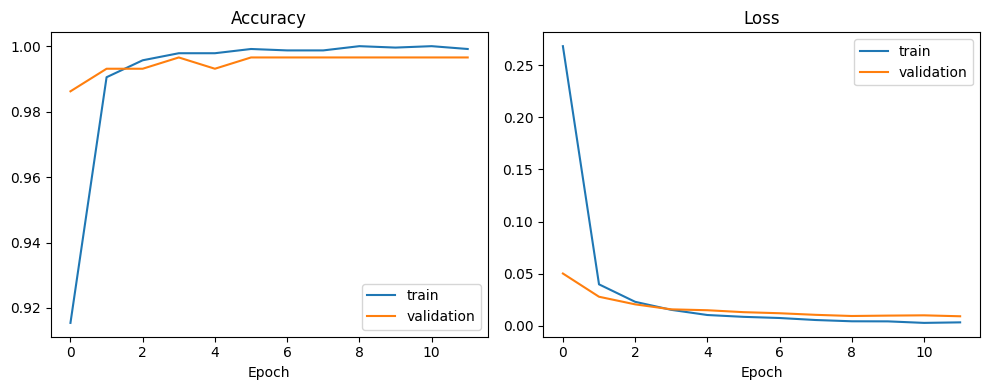

In [12]:
callbacks = [
tf.keras.callbacks.EarlyStopping(
monitor="val_loss", patience=3, restore_best_weights=True
),
tf.keras.callbacks.ReduceLROnPlateau(
monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6
)
]
history = model.fit(
X_train, y_train,
validation_data=(X_val, y_val),
epochs=12,
batch_size=BATCH_SIZE,
callbacks=callbacks,
verbose=1
)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()
plt.tight_layout()
plt.show()

Test loss: 0.0096
Test accuracy: 0.9966
              precision    recall  f1-score   support

         cat       0.95      1.00      0.98        20
         dog       1.00      1.00      1.00        20
     neither       1.00      1.00      1.00       250

    accuracy                           1.00       290
   macro avg       0.98      1.00      0.99       290
weighted avg       1.00      1.00      1.00       290



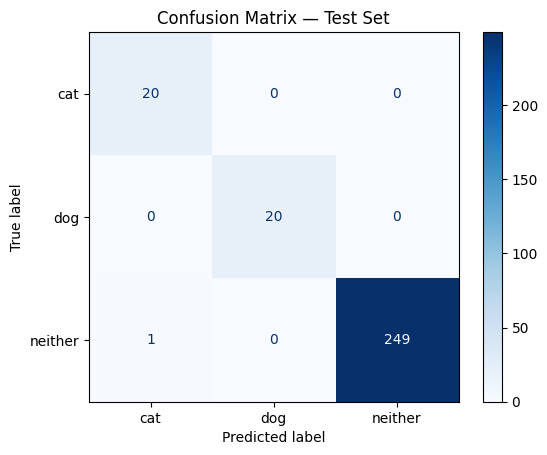

In [13]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
probabilities = model.predict(X_test, batch_size=BATCH_SIZE, verbose=0)
y_pred = probabilities.argmax(axis=1)
print(classification_report(
y_test, y_pred, labels=[0, 1, 2], target_names=LABELS, zero_division=0
))
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=LABELS)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Test Set")
plt.show()

In [15]:
MODEL_PATH = "model.keras"
model.save(MODEL_PATH)
with open("labels.json", "w", encoding="utf-8") as f:
    json.dump(LABELS, f)
print("Saved:", MODEL_PATH)
print("Saved labels.json")

Saved: model.keras
Saved labels.json


In [17]:
from google.colab import files
from PIL import Image
from io import BytesIO
uploaded = files.upload() # choose a JPG or PNG photo
for filename, file_bytes in uploaded.items():
    image = Image.open(BytesIO(file_bytes)).convert("RGB")
    image = image.resize((IMG_SIZE, IMG_SIZE))
    arr = np.asarray(image, dtype="float32") / 255.0
    arr = np.expand_dims(arr, axis=0)
    probs = model.predict(arr, verbose=0)[0]
    best = int(np.argmax(probs))
    print(f"File: {filename}")
    print(f"Prediction: {LABELS[best]} ({probs[best] * 100:.1f}%)")
    print("Scores:", {LABELS[i]: round(float(probs[i]), 4) for i in range(len(LABELS))})

Saving apple.jpg to apple.jpg
Saving dog.jpg to dog.jpg
Saving cat.jpg to cat.jpg
File: apple.jpg
Prediction: neither (99.4%)
Scores: {'cat': 0.0057, 'dog': 0.0005, 'neither': 0.9938}
File: dog.jpg
Prediction: neither (100.0%)
Scores: {'cat': 0.0004, 'dog': 0.0001, 'neither': 0.9995}
File: cat.jpg
Prediction: cat (67.1%)
Scores: {'cat': 0.6706, 'dog': 0.0004, 'neither': 0.329}


In [19]:
base_model.trainable = True
# Freeze most of the backbone; fine-tune only its last 30 layers.
for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fine_history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)

test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Fine-tuned test accuracy: {test_accuracy:.4f}")
model.save("model.keras")

Epoch 1/5
73/73 ━━━━━━━━━━━━━━━━━━━━ 34s 235ms/step - accuracy: 0.9965 - loss: 0.0125 - val_accuracy: 0.9966 - val_loss: 0.0084 - learning_rate: 1.0000e-05
Epoch 2/5
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 1.0000 - loss: 0.0049 - val_accuracy: 0.9966 - val_loss: 0.0083 - learning_rate: 1.0000e-05
Epoch 3/5
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 1.0000 - loss: 0.0034 - val_accuracy: 0.9966 - val_loss: 0.0076 - learning_rate: 1.0000e-05
Epoch 4/5
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 1.0000 - loss: 0.0029 - val_accuracy: 0.9966 - val_loss: 0.0075 - learning_rate: 1.0000e-05
Epoch 5/5
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 1.0000 - loss: 0.0024 - val_accuracy: 0.9931 - val_loss: 0.0071 - learning_rate: 1.0000e-05
Fine-tuned test accuracy: 1.0000


In [20]:
from google.colab import files

files.download("model.keras")
files.download("labels.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>